# Homework 5 - MTH 602 - Coding Questions

William Girard

Due Date: Wednesday, October 4th, 2026

## Using GMM as a geometric and probabilistic classifier

### Recap of the previous assignment (context)

In the previous homework (HW4, problem 2, stage 2) you generated and analyzed a 2-component 2D Gaussian mixture model (GMM) and sampled from the fitted GMM. We also saw how sklearn was able to use the GMM model as a classifier by calling the function

```python
predicted_labels = gmm.predict(X_test)
```

This assignment continues with this classification task. You will now use a fitted *two-component* GMM as a **classifier** in two ways:

- (A) to define a simple geometric decision boundary from the two means;
- (B) to define a probabilistic classifier using the GMM posterior.

Both approaches are discussed in the book as the two main ways of handling classification.

### Setup and notation

You will work in $\mathbb{R}^2$ with coordinates $\vec{x} = (x_1, x_2)$. Reuse your data generator and fitting code from the previous assignment (or use the snippets below). Unless otherwise specified, use a single fixed split with a fixed random seed for all methods discussed below. This will ensure reproducibility.

```python
# Provided in HW4:
def sample_2d_gaussian(mu, Sigma, n, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    return rng.multivariate_normal(mean=mu, cov=Sigma, size=n)
```

### Data for this assignment

Use a similar (**Note**: These values are different than homework 4) ground-truth mixture:

$$
w = (0.2, 0.8), \quad \mu_1 = (0, 0), \; \Sigma_1 = \begin{bmatrix} 1 & 0.8 \\ 0.8 & 1.5 \end{bmatrix}; \qquad \mu_2 = (2, 2), \; \Sigma_2 = \begin{bmatrix} 1.2 & -0.5 \\ -0.5 & 0.8 \end{bmatrix}.
$$

Draw $N = 3000$ labeled samples by first sampling the component index $y \in \{1, 2\}$ with probabilities $(0.2, 0.8)$ and then sampling $\vec{x} \mid y = k \sim \mathcal{N}(\mu_k, \Sigma_k)$. Split once into train (80%) and test (20%) using a fixed random seed. See homework 4 and the GMM demo notebook for how to do this.

### Training the Gaussian mixture model (10 POINTS TOTAL)

1. Fit the GMM with $K=2$ components on the training points.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def sample_2d_gaussian(mu, Sigma, n, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    return rng.multivariate_normal(mean=mu, cov=Sigma, size=n)

In [3]:
rng = np.random.default_rng(42)

# given values
w = np.array([0.2, 0.8])
mus = [np.array([0.0, 0.0]), np.array([2, 2])]
Sigmas = [np.array([[1.0, 0.8], [0.8, 1.5]]),
          np.array([[1.2, -0.5], [-0.5, 0.8]])]
N = 3000


z = rng.choice(len(w), size=N, p=w) # draw 0 or 1 N times with weights
values, counts = np.unique(z, return_counts=True)
print(f'0-type: {counts[0]} - 1-type: {counts[1]}') # should be close to 600/2400

0-type: 616 - 1-type: 2384


In [4]:
from sklearn.model_selection import train_test_split 

X_1 = sample_2d_gaussian(mus[0], Sigmas[0], counts[0], rng)
X_2 = sample_2d_gaussian(mus[1], Sigmas[1], counts[1], rng)

X = np.vstack([X_1, X_2])
y = np.concatenate([np.full(counts[0], 1), np.full(counts[1], 2)])   # true class 1 / 2

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
from sklearn.mixture import GaussianMixture

gk2 = GaussianMixture(n_components=2, covariance_type='full',
n_init=10, random_state=0).fit(X_train)

2. GMM components are unlabeled; align them to classes using only the training set data. Use the nearest-mean rule: with fitted means $\hat{\mu}^{(0)}, \hat{\mu}^{(1)}$ and known true means $\mu_1, \mu_2$, map the pair $(\hat{\mu}^{(0)}, \hat{\mu}^{(1)})$ to $(\mu_1, \mu_2)$ by the minimum total Euclidean distance. In code:

```python
M  = g2.means_
d0 = np.linalg.norm(M[0]-mu1) + np.linalg.norm(M[1]-mu2)
d1 = np.linalg.norm(M[1]-mu1) + np.linalg.norm(M[0]-mu2)
if d0 <= d1:
    class_to_component = {1: 0, 2: 1}
    component_to_class = {0: 1, 1: 2}
else:
    class_to_component = {1: 1, 2: 0}
    component_to_class = {1: 1, 0: 2}
```

These mappings will come in handy as you write code to solve this problem. In particular, we can now refer to $\hat{\mu}_1$ as the mean for the Gaussian describing class 1.

In [6]:
M = gk2.means_

d0 = np.linalg.norm(M[0]-mus[0]) + np.linalg.norm(M[1]-mus[1])
d1 = np.linalg.norm(M[1]-mus[0]) + np.linalg.norm(M[0]-mus[1])

if d0 <= d1:
    class_to_component = {1: 0, 2: 1}
    component_to_class = {0: 1, 1: 2}
else:
    class_to_component = {1: 1, 2: 0}
    component_to_class = {1: 1, 0: 2}

component_to_class

{0: 1, 1: 2}

3. Verify the correctness of your GMM model and the class-to-component mapping. Provide strong evidence that everything is working. You should decide what evidence to provide, but it should convince any reasonable reader beyond any doubt that you have a working GMM model with the correct labels.

In [7]:
# check GMM parameters vs. true params using class mapping 

for k in (1, 2):
    c = class_to_component[k]
    print(f'\nClass {k}:\n')
    print(f'GMM weight: {gk2.weights_[c]} - true weight: {w[k-1]}')
    print(f'GMM means: {gk2.means_[c]} - true means: {mus[k-1]}')
    print(f'GMM covariance:\n{gk2.covariances_[c]}\ntrue covariance:\n{Sigmas[k-1]}')



Class 1:

GMM weight: 0.18232838875934737 - true weight: 0.2
GMM means: [-0.11889383 -0.14134441] - true means: [0. 0.]
GMM covariance:
[[0.86653649 0.61189674]
 [0.61189674 1.17911749]]
true covariance:
[[1.  0.8]
 [0.8 1.5]]

Class 2:

GMM weight: 0.8176716112406527 - true weight: 0.8
GMM means: [2.01572848 2.00171268] - true means: [2 2]
GMM covariance:
[[ 1.25004579 -0.51828827]
 [-0.51828827  0.7871896 ]]
true covariance:
[[ 1.2 -0.5]
 [-0.5  0.8]]


Seems the class mapping worked properly. I can use variable `c` from the `class_to_component` dictionary to get the predicted parameters from the GMM and the true parameters. They all seems to match properly, the means are especically close, while the covariances are slightly further apart, but the class mapping clearly worked.

In [8]:
# now time to test performance using accuracy + confusion matrix

y_true = y_train # leave unchanged with 2 and 1 labels
predictions = gk2.predict(X_train) 

print(y_true, predictions)


[2 2 1 ... 2 2 2] [1 1 0 ... 1 1 1]


Computed accuracy is 95.833%


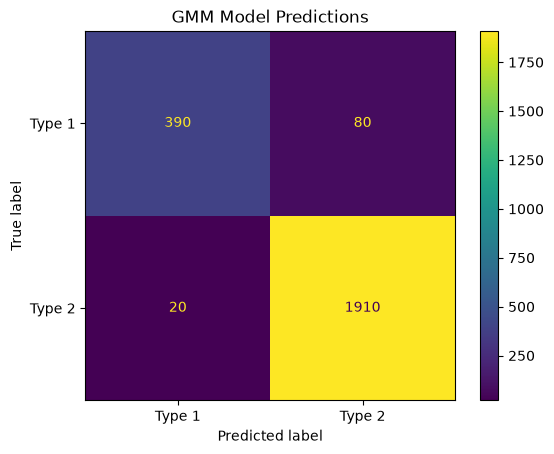

In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay 

# can be seen that the labels don't match, one is 2s and 1s, while the other is 1s and 0s
# fix mapping, then compute accuracy

y_pred = [component_to_class[c] for c in predictions]
accuracy = 100 * accuracy_score(y_true, y_pred) 
print(f'Computed accuracy is {accuracy:.3f}%')

cm = confusion_matrix(y_true, y_pred, labels=[1, 2]) 
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Type 1", "Type 2"])
disp.plot()
plt.title("GMM Model Predictions")
plt.show()

Overall, everything looks reasonable. 95.833% accuracy is reasonable for a GMM and the label mapping clearly worked correctly, as proven in the parameter printing. My guess for the dip in accuracy is that that the two Gaussians have some point overlap, where it isn't possible to 100% accurately tell which point came from where (in other words, there isn't a decision boundary that perfectly separates the two Gaussians).

###  Geometric classification (20 POINTS TOTAL)

Let $\hat{\mu}_1, \hat{\mu}_2 \in \mathbb{R}^2$ be the two fitted means after class label alignment (so $\hat{\mu}_1$ is the mean for the Gaussian describing class 1). Define

$$\hat{r} = \frac{\hat{\mu}_2 - \hat{\mu}_1}{\|\hat{\mu}_2 - \hat{\mu}_1\|_2}, \qquad m = \frac{\hat{\mu}_1 + \hat{\mu}_2}{2}.$$

Here, $\hat{r}$ is the unit direction vector pointing from $\hat{\mu}_1$ to $\hat{\mu}_2$ and $m$ is the midpoint between the means. Classify a point $x$ by which side of the perpendicular bisector it falls on:

$$\hat{y}_{\text{geom}}(x) = \begin{cases} 1, & \langle x - m, \hat{r} \rangle < 0 \\ 2, & \langle x - m, \hat{r} \rangle \ge 0\,. \end{cases}$$

The decision boundary you constructed here is called a perpendicular-bisector decision boundary.

Tasks:

1. Plot the geometric decision boundary together with the training points colored by their true class. This is a
visual check that the decision boundary is reasonable.

In [10]:
# get u2 and u1

mu_1 = gk2.means_[class_to_component[1]]
mu_2 = gk2.means_[class_to_component[2]]

mu_1, mu_2

(array([-0.11889383, -0.14134441]), array([2.01572848, 2.00171268]))

In [11]:
r = (mu_2 - mu_1)/(np.linalg.norm(mu_2-mu_1))
m = (mu_1+mu_2)/2

def classify_geom(X):
    s = (X-m) @ r
    return np.where(s < 0, 1, 2)

y_hat = classify_geom(X_train)
y_hat

array([2, 2, 1, ..., 2, 2, 2], shape=(2400,))

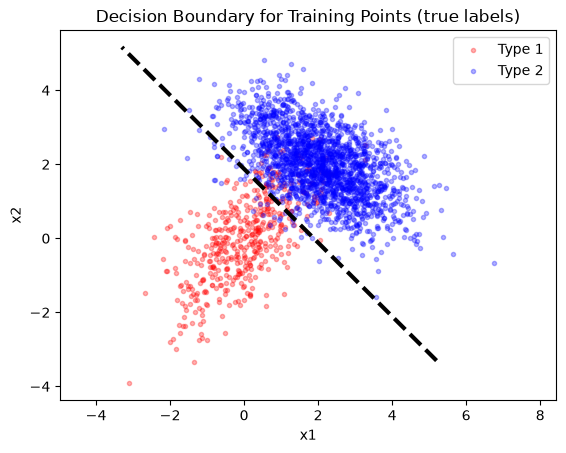

In [12]:
# plot the linear decision boundary
t_hat = (-r[1], r[0]) 
s = np.linspace(-6, 6, 100)
line = m + s[:, None] * t_hat   
plt.plot(line[:,0], line[:,1], linewidth=3, color="black", linestyle="--")

# true training points, class = 1
X_train_1 = X_train[y_train==1]
plt.scatter(X_train_1[:, 0], X_train_1[:, 1], color="red", s=9, alpha=0.3, label="Type 1")

# true training points, class = 2
X_train_2 = X_train[y_train==2]
plt.scatter(X_train_2[:, 0], X_train_2[:, 1], color="blue", s= 9, alpha=0.3, label = "Type 2")
plt.axis('equal')
plt.title('Decision Boundary for Training Points (true labels)')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.show()

2. Plot the geometric decision boundary together with the testing points colored by their true class. This is
the result of using the classifier. This should also show misclassified data as being on the wrong side of the
decision boundary.

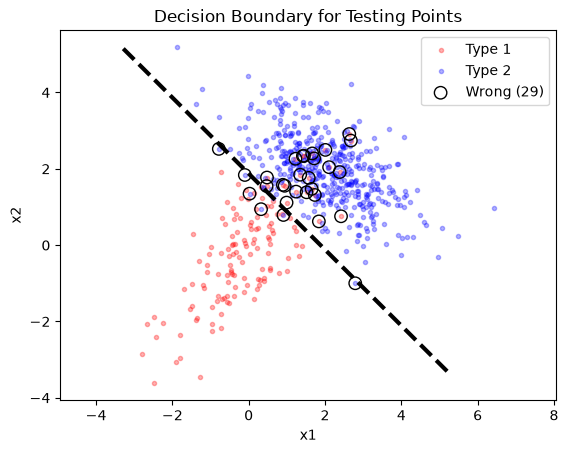

In [13]:
y_pred = classify_geom(X_test) 
wrong = y_pred != y_test # array of false/true 

# plot the linear decision boundary
t_hat = (-r[1], r[0]) 
s = np.linspace(-6, 6, 100)
line = m + s[:, None] * t_hat   
plt.plot(line[:,0], line[:,1], linewidth=3, color="black", linestyle="--")

# true testing points, class = 1
X_test_1 = X_test[y_test==1]
plt.scatter(X_test_1[:, 0], X_test_1[:, 1], color="red", s=9, alpha=0.3, label="Type 1")

# true testing points, class = 2
X_test_2 = X_test[y_test==2]
plt.scatter(X_test_2[:, 0], X_test_2[:, 1], color="blue", s= 9, alpha=0.3, label = "Type 2")

# plot wrong points on top with a marker
X_wrong = X_test[wrong]
plt.scatter(X_wrong[:, 0], X_wrong[:, 1], facecolors='none', edgecolors='k', s=80, label=f'Wrong ({wrong.sum()})')

plt.axis('equal')
plt.title('Decision Boundary for Testing Points')
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.show()

3. Compute and report the confusion matrix for the testing data.

Computed accuracy is 95.167%


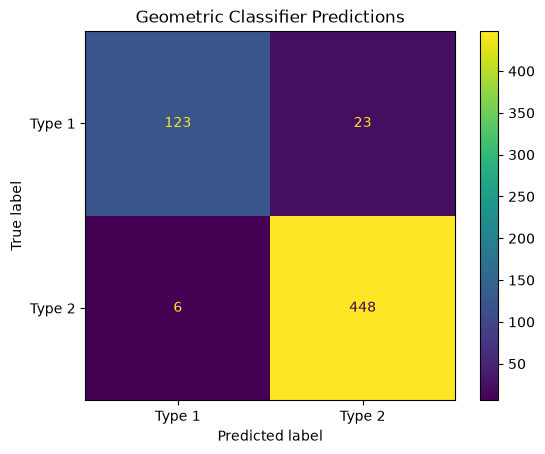

In [14]:

y_pred = classify_geom(X_test)
y_true = y_test

accuracy = 100 * accuracy_score(y_true, y_pred) 
print(f'Computed accuracy is {accuracy:.3f}%')

cm = confusion_matrix(y_true, y_pred, labels=[1, 2]) 
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Type 1", "Type 2"])
disp.plot()
plt.title("Geometric Classifier Predictions")
plt.show()

Accuracy is lower than the previous part (95.167 vs 95.833). Also, it seems type 1/class 1 is harder to predict. There are 123+23 = 146 true labels. If we denote Type 1 as positive (arbitrary), then we get a TPR of 123/146 $\approx$ 84%. If type 2 is the negative class, then the true negative rate is 448/(448+6) $\approx$ 98.6%, a large difference.

### Probabilistic GMM classifier with thresholding & ROC (20 TOTAL POINTS)

Your GMM model can also be used as a probabilistic classifier. To see this, we first recall from the book (See Eq 3.115 and the first equality of 5.40) the following formula: For a $K=2$ component GMM with parameters $(\hat{\pi}_k, \hat{\mu}_k, \hat{\Sigma}_k)_{k=1}^{2}$, for any $x$,

$$
P(k \mid x) = \frac{\hat{\pi}_k \, \mathcal{N}(x \mid \hat{\mu}_k, \hat{\Sigma}_k)}{\sum_{\ell=1}^{2} \hat{\pi}_\ell \, \mathcal{N}(x \mid \hat{\mu}_\ell, \hat{\Sigma}_\ell)}.
$$

$P(k \mid x)$ is the probability of the data $x$ belonging to class $k$. It can be computed directly from sklearn's GMM function:

```python
comp_idx_for_class2 = class_to_comp[2]
proba_class2 = g2.predict_proba(X_test)[:, comp_idx_for_class2]
```

$P(2 \mid x)$ is the class-2 probability and, for a threshold $\tau \in [0, 1]$,

$$
\hat{y}_{\text{prob}}(x; \tau) = \begin{cases} 2, & P(2 \mid x) \ge \tau \\ 1, & P(2 \mid x) < \tau\,. \end{cases}
$$

1. Compute the confusion matrix over the testing dataset using a reasonable threshold of 𝜏 = 0.5.

In [15]:
def classify_prob(X, thresh):
    comp_idx_for_class2 = class_to_component[2]
    proba_class2 = gk2.predict_proba(X)[:, comp_idx_for_class2]
    
    return np.where(proba_class2 >= thresh, 2, 1)

y_pred = classify_prob(X_test, thresh=0.5)
outputs = np.unique(y_pred, return_counts=True)
outputs[1], np.unique(y_test, return_counts=True)[1] # predicted counts vs. true test counts (146/454)

(array([124, 476]), array([146, 454]))

Computed accuracy is 95.000%


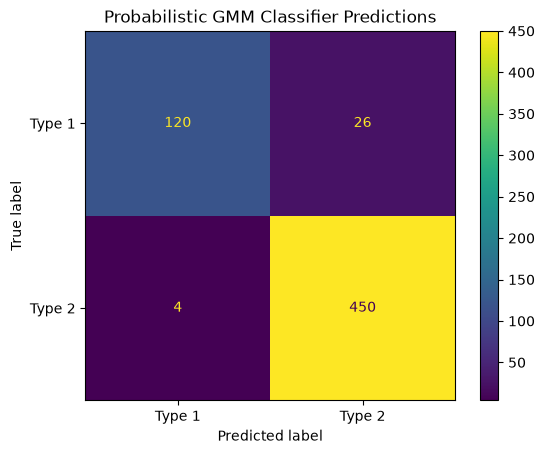

In [16]:
y_true = y_test 

accuracy = 100 * accuracy_score(y_true, y_pred) 
print(f'Computed accuracy is {accuracy:.3f}%')

cm = confusion_matrix(y_true, y_pred, labels=[1, 2]) 
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Type 1", "Type 2"])
disp.plot()
plt.title("Probabilistic GMM Classifier Predictions")
plt.show()

No Skill: AUC = 0.500
Prob. GMM: AUC = 0.965

Point selection: 
tau: 0.9192 - FPR: 0.1027 - TPR: 0.9339
tau: 0.9164 - FPR: 0.1096 - TPR: 0.9339
tau: 0.9011 - FPR: 0.1096 - TPR: 0.9449
tau: 0.8871 - FPR: 0.1164 - TPR: 0.9449
tau: 0.8628 - FPR: 0.1164 - TPR: 0.9515
tau: 0.8539 - FPR: 0.1233 - TPR: 0.9515
tau: 0.8324 - FPR: 0.1233 - TPR: 0.9626
tau: 0.8187 - FPR: 0.1507 - TPR: 0.9626
tau: 0.7042 - FPR: 0.1507 - TPR: 0.9824
tau: 0.6753 - FPR: 0.1575 - TPR: 0.9824
tau: 0.6043 - FPR: 0.1575 - TPR: 0.9912


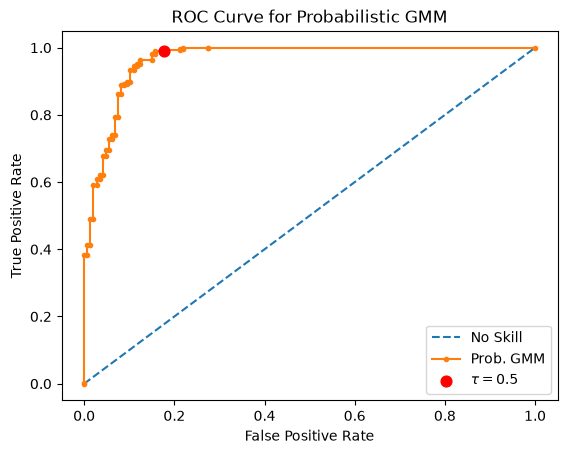

In [17]:
from sklearn.metrics import roc_auc_score, roc_curve

# no skill probability, predict majority
ns_probs = [2 for _ in y_test]

# raw probabilities
comp_idx_for_class2 = class_to_component[2]
gmm_probs = gk2.predict_proba(X_test)[:, comp_idx_for_class2]

ns_auc = roc_auc_score(y_test, ns_probs)
gmm_auc = roc_auc_score(y_test, gmm_probs)

# summarize scores
print('No Skill: AUC = %.3f' % (ns_auc))
print('Prob. GMM: AUC = %.3f' % (gmm_auc))

# calculate roc curves
ns_fpr, ns_tpr, _ = roc_curve(y_test, ns_probs, pos_label=2)
gmm_fpr, gmm_tpr, gmm_thresh = roc_curve(y_test, gmm_probs, pos_label=2)

# plot the roc curve for the model
plt.plot(ns_fpr, ns_tpr, linestyle='--', label='No Skill')
plt.plot(gmm_fpr, gmm_tpr, marker='.', label='Prob. GMM')

# mark the tau = 0.5 operating point (positive class = 2)
y_05 = classify_prob(X_test, thresh=0.5)
fpr_05 = np.mean(y_05[y_test == 1] == 2)
tpr_05 = np.mean(y_05[y_test == 2] == 2)
plt.scatter(fpr_05, tpr_05, color='red', s=60, zorder=3, label=r'$\tau = 0.5$')

print('\nPoint selection: ')
for fpr, tpr, tau in zip(gmm_fpr, gmm_tpr, gmm_thresh):
    if(tpr >= 0.9 and fpr <=0.16):
        print(f'tau: {tau:.4f} - FPR: {fpr:.4f} - TPR: {tpr:.4f}')


plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Probabilistic GMM')
plt.legend()
plt.show()

A few big points about the above graph:
- Class 2 is treated as positive, so FPR is how many class 1 points are incorrectly labeled as class 2. The TPR is the percentage of class 2 points that are correctly classified as class 2. 
- The thresholds are also reported for the point selection.

The dotted blue is the "No Skill" baseline, where it predicts 2 for every single datapoint, since that is the majority class. Clearly, the probabilistic GMM easily outperforms the baseline with an AUC of 0.965. This is a strong AUC, since it ranges from 0 --> 1.0, with 0.5 as the baseline. A perfect model would have a point at (0, 1), representing 0% FPR and 100% TPR. 

The best threshold/point decision depends on whether class 1 or 2 is more important to accurately classify. But a strong choice is balancing TPR/FPR, in this case, the model achieves high 99% TPR with only ~15% FPR at threshold of 0.6. Or, if you want less false positives, you could achieve 94% TPR and 10% FPR with threshold = 0.9.

### Comparison: Probabilistic vs geometric classifier (10 TOTAL POINTS)

In a few sentences.... (i) compare the geometric and probabilistic classifiers in terms of performance, (ii) does this
dataset constitute an easy or hard classification task, and (iii) is class-1 or class-2 more difficult to predict and
intuitively why do you think so?

(i) Direct comparison has the geometric model at 95.167% accuracy and the probabilistic one at 95% accuracy. The confusion matrix for the probabilistic classifier also has three more false positives (predicted class 2, but was actually class 1) when compared to the geometric model. Which is important if you care about correctly classifying the small class 1.

(ii) In the grand scheme of things, this is a relatively simple classification task. There are only two Gaussians, while real world datasets (like the star (pulsar?) example shown in class) require 5+ Gaussians to accurately describe the entire pulsar population. However, the nature of Gaussian 1, which is what the next question discusses, makes things more difficult. In fact, some points appear entirely ambiguous, making perfect accuracy impossible with the given knowledge. Overall though, an accuracy of 95% is reasonable and points to the task not being terribly difficult. 

(iii) Class 1 is more difficult to predict. Intuitively, there are four times less points in class 1 when compared to class 2. I embedded the graph from earlier in this homework, since it is very useful for this question. It can be observed that class 1 stretches much further (wider) than class 2, with some red points even reaching the outer edges of the blue cluster. When using the geometric model, 23/29 wrong classifications on the testing dataset came from class 1 being predicted as class 2, as is shown below. The probabilistic model has the same limitation. If we treat class 2 as positive, the classifier achieved a true positive rate of 450/454 = 99.11%. On the other hand, the true negative rate (class 1) is 120/146 = only 82.2%. So, from both a visual and numerical point-of-view, class 1 is harder to predict for both the probabilistic and geometric classifiers.

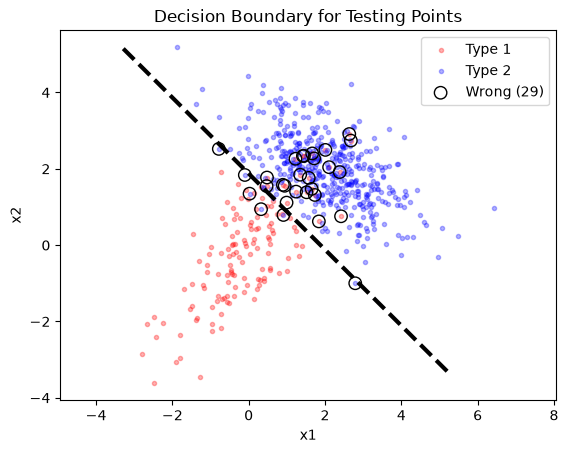

## Particle physics: classification of a parent particle from Two-Body Decay Kinematics (20 points + bonus)

**Grading.** Any reasonable attempt earns 20 points.

**High-level background information.** In high-energy particle physics, unstable "parent" particles are created in collisions (at places like Fermilab or CERN) and promptly decay into lighter "daughter" particles whose energies and momenta are measured by detectors. Because the parent often cannot be observed directly, we infer its identity from the daughters' kinematics using conservation of energy-momentum. In this challenge, each event contains two massless daughters (e.g., photons), and the unknown parent is one of two possible parent particles with different masses.

Its not expected that any student will have worked in particle physics or has detailed knowledge of this domain. Rather, you can approach this as a machine learning problem. You have raw data (energy and momentum of the daughter particles) and you need to classify the parent particle. Students with a physics background may wish to construct "physics-informed" features such as invariant mass, transverse momentum, and opening angle, etc... and using these features as the raw data upon which the classifier is trained.

**Problem statement.** An unknown parent particle is either particle **A** or particle **B**. These particles have distinct masses.

Your dataset records instances of particle decay. Each particle-decay event has two massless daughters (e.g., photons). From the daughters' energy and momentum (for physics students, these are technically four-vectors), classify the parent particle as *A* or *B*.

- `hw5_train.csv`: Each column is a recorded decay event. The first daughter particle has an energy, $E_1$, and momentum, $(p_{x1}, p_{y1}, p_{z1})$. The second daughter particle has an energy, $E_2$, and momentum, $(p_{x2}, p_{y2}, p_{z2})$. Therefore, each column's data is `E1,px1,py1,pz1,E2,px2,py2,pz2,label` (label $\in$ {A,B}).
- `hw5_test.csv`: same kinematics, no labels.
- The data is recorded in the "lab frame". In the rest frame of the parent particle, the decay is isotropic.

**Suggested line of attack.** As with all challenge problems, you should tackle this as you see fit and according to your skills. If you have more of an ML background, you might focus on building sophisticated classifiers. Presumably probabilistic ones that work in a non-linear feature space will be best. If you have a physics background, you might attempt to construct physics-inspired features such as the invariant mass, for example.

**Scoring for the bonus challenge.** For the test set, submit two numbers: your predicted counts of parent types A and B: `N_A_pred`, `N_B_pred`.

If you have a probabilistic classifier, you can either convert to a specific class using a threshold or compute so-called "soft" counts from the posteriors: $N\_B\_\text{pred} = \sum_{j=1}^{N_\text{test}} p(B \mid x_j)$ and $N\_A\_\text{pred} = N_\text{test} - N\_B\_\text{pred}$.

Submissions are scored by absolute count error

$$
\text{Score} = \left|N\_A\_\text{pred} - N_A^\text{true}\right| + \left|N\_B\_\text{pred} - N_B^\text{true}\right|,
$$

so lower is better. And of course $N\_A\_\text{pred} + N\_B\_\text{pred} = N_\text{test}$.

In [18]:
# load data and inspect 

df_train = pd.read_csv('train_hw5.csv') # labeled points
df_test = pd.read_csv('test_hw5.csv') # points to classify

df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   E1      20000 non-null  float64
 1   px1     20000 non-null  float64
 2   py1     20000 non-null  float64
 3   pz1     20000 non-null  float64
 4   E2      20000 non-null  float64
 5   px2     20000 non-null  float64
 6   py2     20000 non-null  float64
 7   pz2     20000 non-null  float64
 8   label   20000 non-null  str    
dtypes: float64(8), str(1)
memory usage: 1.4 MB


In [19]:
# dataset contains a label and all entries are non-null
# test should have no label (8 total columns)
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   E1      500 non-null    float64
 1   px1     500 non-null    float64
 2   py1     500 non-null    float64
 3   pz1     500 non-null    float64
 4   E2      500 non-null    float64
 5   px2     500 non-null    float64
 6   py2     500 non-null    float64
 7   pz2     500 non-null    float64
dtypes: float64(8)
memory usage: 31.4 KB


In [20]:
# investigate class counts for training dataset

label = df_train['label']
label.value_counts()

label
B    15986
A     4014
Name: count, dtype: int64

Highly imbalanced, ~4 times more B particles than A particles. Should state here that I am tackling this from a ML point-of-view, since I have no knowledge of particular physics. 

I think I will employ the "random upsampling" approach to this dataset. I will use this medium article as reference: https://medium.com/data-science/class-imbalance-strategies-a-visual-guide-with-code-8bc8fae71e1a.

In [21]:
# seed for reproduciability
seed = 42

In [22]:
from sklearn.model_selection import train_test_split

# separate data into x, y
# create validation data, testing data is unlabeled

columns = df_train.shape[1]
X = df_train.iloc[:,0:columns-1] # exclude last column
y = df_train.iloc[:,-1] # select only last column

# test data is unlabeled, only features
X_test = df_test

X_train, X_val, y_train, y_val = train_test_split(X, y, random_state=seed, test_size=0.15)

print(f'X train: {X_train.shape}, y train: {y_train.shape}, X validation: {X_val.shape}, y validation: {y_val.shape}')

X train: (17000, 8), y train: (17000,), X validation: (3000, 8), y validation: (3000,)


In [23]:
# need a Python library based on scikit-learn called imbalanced-learn for the class balancing

!pip install -U imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [imbalanced-learn]


In [24]:
from imblearn.over_sampling import RandomOverSampler

# important: only over sample testing data, leave validation normal for real-world accuracy
ros = RandomOverSampler(random_state=seed)
X_train_ros, y_train_ros = ros.fit_resample(X_train, y_train)
y_train_ros.value_counts() # now should be exactly balanced between A, B

label
B    13592
A    13592
Name: count, dtype: int64

In [25]:
from sklearn.preprocessing import StandardScaler 
from sklearn.preprocessing import LabelEncoder

# scale data using mean and std.
scaler = StandardScaler().fit(X_train_ros)
# encode labels (B --> 1, A --> 0)
le = LabelEncoder().fit(y_train_ros)

# training
X_train_ros_scaled, y_train_ros = scaler.transform(X_train_ros), le.transform(y_train_ros)

#validation
X_val_scaled, y_val = scaler.transform(X_val), le.transform(y_val)

X_train_ros_scaled[0:4], y_train_ros[0:4]

(array([[-0.46895261, -1.47433871, -0.33993701, -0.07770291, -0.17995403,
          1.32086033,  1.20509156,  0.38443206],
        [ 0.13515691,  1.32210634,  1.21196717, -0.71956902,  0.23277585,
         -1.22451484, -0.94344943, -0.84549816],
        [-0.21766753, -1.86684785,  0.0230577 , -0.32190807, -0.36073171,
          1.18735982, -1.24993663, -0.11998429],
        [ 0.51123502, -0.46322784, -1.03210778,  1.12233983, -0.7281423 ,
          0.57822625,  0.16088522, -0.16131509]]),
 array([1, 1, 1, 1]))

In [26]:
# install xgboost library to use XGBoost classifier
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 4.9 MB/s  0:00:11a 0:00:01m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 305.1/305.1 MB 2.9 MB/s  0:02:00 eta 0:00:010:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]━━━ 1/2 [xgboost]


In [27]:
# features should be ready for a classifier
# first thought is XGBoost (gradient boosting classifier) 
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# train model and compute accuracy
clf = XGBClassifier(random_state=seed).fit(X_train_ros_scaled, y_train_ros) # has numerous hyperparameters, will tune later
train_acc = clf.score(X_train_ros_scaled, y_train_ros) # returns accuracy score

y_pred = clf.predict(X_val_scaled) # predict on unseen dataset (similar to test set)
print(f'Training accuracy: {100*train_acc:.3f}%')
print(f'Validation accuracy: {100*accuracy_score(y_val, y_pred):.3f}%')
print(f'Validation precision: {100*precision_score(y_val, y_pred):.3f}%')
print(f'Validation recall: {100*recall_score(y_val, y_pred):.3f}%')
print(f'Validation F1: {100*f1_score(y_val, y_pred):.3f}%')

Training accuracy: 99.117%
Validation accuracy: 91.467%
Validation precision: 93.776%
Validation recall: 95.656%
Validation F1: 94.706%


Metrics are pretty solid to start. The model obtains 91.467% accuracy and a reasonable F1 score of 94.706%. However, the model is slightly overfit. 99.117% training accuracy against 91.467% validation (testing) accuracy is a significant enough gap. I will try to optimize the parameters to hopefully improve validation accuracy and then address the overfitting.

In [28]:
# now lets try to improve those validation metrics through grid search
# credit for param grid: https://www.youtube.com/watch?v=9Ee4PDaqpUs

# these parameters are saved in a file called "best_params.txt"
# WARNING: the grid search takes a while to complete if you want to run it yourself, ~11 minutes on my PC

from sklearn.model_selection import GridSearchCV


"""
param_grid = {
    'n_estimators': [50, 100, 200, 500, 1000],
    'learning_rate': [0.1, 0.3, 0.6, 0.8, 1.0],
    'max_depth': [1, 3, 6, 10],
    'reg_alpha': [0.0, 0.1, 0.5, 1.0],
    'reg_lambda': [0.1, 0.5, 1.0, 1.5]
}

g = GridSearchCV(XGBClassifier(random_state=seed), param_grid, cv=5, n_jobs=-1)

g.fit(X_train_ros_scaled, y_train_ros)
cls_params = g.best_params_
cls_params
"""

"\nparam_grid = {\n    'n_estimators': [50, 100, 200, 500, 1000],\n    'learning_rate': [0.1, 0.3, 0.6, 0.8, 1.0],\n    'max_depth': [1, 3, 6, 10],\n    'reg_alpha': [0.0, 0.1, 0.5, 1.0],\n    'reg_lambda': [0.1, 0.5, 1.0, 1.5]\n}\n\ng = GridSearchCV(XGBClassifier(random_state=seed), param_grid, cv=5, n_jobs=-1)\n\ng.fit(X_train_ros_scaled, y_train_ros)\ncls_params = g.best_params_\ncls_params\n"

In [29]:
# load saved param grid file
import ast

with open("best_params.txt", "r") as f:
    cls_params = ast.literal_eval(f.read())

cls_params

{'learning_rate': 0.3,
 'max_depth': 10,
 'n_estimators': 1000,
 'reg_alpha': 0.1,
 'reg_lambda': 1.5}

In [30]:
# create a new classifier with best parameters

clf_best = XGBClassifier(**cls_params, random_state=seed).fit(X_train_ros_scaled, y_train_ros)

train_acc = clf_best.score(X_train_ros_scaled, y_train_ros) # returns accuracy score

y_pred = clf_best.predict(X_val_scaled) # predict on unseen dataset (similar to test set)
print(f'Training accuracy: {100*train_acc:.3f}%')
print(f'Validation accuracy: {100*accuracy_score(y_val, y_pred):.3f}%')
print(f'Validation precision: {100*precision_score(y_val, y_pred):.3f}%')
print(f'Validation recall: {100*recall_score(y_val, y_pred):.3f}%')
print(f'Validation F1: {100*f1_score(y_val, y_pred):.3f}%')

Training accuracy: 100.000%
Validation accuracy: 94.567%
Validation precision: 94.745%
Validation recall: 98.663%
Validation F1: 96.665%


In [31]:
y_pred_classes = np.unique_counts(y_pred)[1]
y_true_classes = np.unique_counts(y_val)[1]
print(f'Predicted A: {y_pred_classes[0]}, True A: {y_true_classes[0]} - Predicted B: {y_pred_classes[1]}, True B: {y_true_classes[1]}')

Predicted A: 507, True A: 606 - Predicted B: 2493, True B: 2394


In [32]:
# model appears to be somewhat over (6 percent accuracy difference between training and validation) but much better than before
# try some overfitting strategies

# subsample and colsample_bytes (dropout) + early stopping (reduces overfitting)
clf_tuned = XGBClassifier(**cls_params, early_stopping_rounds=40, eval_metric="logloss", random_state=seed)

# use the validation data for early stopping
clf_tuned.fit(X_train_ros_scaled, y_train_ros, eval_set=[(X_val_scaled, y_val)], verbose=False)
best_iteration = clf_tuned.best_iteration
print(f'Best Iteration: {best_iteration}') 

y_pred = clf_tuned.predict(X_val_scaled, iteration_range=(0, best_iteration)) # use best iteration for prediction
print(f'Training accuracy: {100*train_acc:.3f}%')
print(f'Validation accuracy: {100*accuracy_score(y_val, y_pred):.3f}%')
print(f'Validation precision: {100*precision_score(y_val, y_pred):.3f}%')
print(f'Validation recall: {100*recall_score(y_val, y_pred):.3f}%')
print(f'Validation F1: {100*f1_score(y_val, y_pred):.3f}%')

Best Iteration: 674
Training accuracy: 100.000%
Validation accuracy: 94.233%
Validation precision: 94.367%
Validation recall: 98.663%
Validation F1: 96.467%


Doesn't seem early stopping helped that much in this case. Model still maintains 100% training accuracy and the validation accuracy stays virtually identical. One thing left to try is to directly apply class balancing to the weights themselves, rather than the data.

In [33]:
# one thing I could try is using weight scaling for XGBoost directly, instead of oversampling 

scaler = StandardScaler().fit(X_train)
le = LabelEncoder().fit(y_train)

X_train_scaled = scaler.transform(X_train) 
y_train = le.transform(y_train) 

y_train_counts = np.unique_counts(y_train)[1]
weight = y_train_counts[0]/y_train_counts[1]

print('Class weight ratio: ', weight)

clf = XGBClassifier(**cls_params, scale_pos_weight=weight, random_state=seed).fit(X_train_scaled, y_train)

train_acc = clf.score(X_train_scaled, y_train) # returns accuracy score

y_pred = clf.predict(X_val_scaled) # predict on unseen dataset (similar to test set)
print(f'Training accuracy: {100*train_acc:.3f}%')
print(f'Validation accuracy: {100*accuracy_score(y_val, y_pred):.3f}%')
print(f'Validation precision: {100*precision_score(y_val, y_pred):.3f}%')
print(f'Validation recall: {100*recall_score(y_val, y_pred):.3f}%')
print(f'Validation F1: {100*f1_score(y_val, y_pred):.3f}%')

Class weight ratio:  0.2507357268981754
Training accuracy: 100.000%
Validation accuracy: 91.000%
Validation precision: 90.075%
Validation recall: 99.708%
Validation F1: 94.647%


Validation accuracy decreased by a lot, the precision also went down while the recall increased. Definitely not an improvement over random upsampling.

In [34]:
# predict for unseen data and print out my class counts 

scaler = StandardScaler().fit(X_test)

X_test_scaled = scaler.transform(X_test) 
y_test_pred = clf_best.predict(X_test_scaled) 

y_counts = np.unique_counts(y_test_pred)[1]
print(f'Final Forecasted Values: {y_counts[0]} A Particles - {y_counts[1]} B Particles')

Final Forecasted Values: 119 A Particles - 381 B Particles
